In [1]:
# Cell 1: environment check — needs requirements-audio.txt, not requirements-train.txt
import sys
from importlib.metadata import version

print(f"python      {sys.executable}")
print(f"birdnet     {version('birdnet')}")
print(f"sklearn     {version('scikit-learn')}")


python      /Users/nikhilkunapareddy/.venvs/loonet-audio/bin/python
birdnet     1.3.1
sklearn     1.9.1


In [2]:
# Cell 2: write train/val lists — 80/20 by recording within each source, so no
# recording has windows on both sides of the split
from pathlib import Path
import csv, random, yaml

DS = next(p / "data/annotated/looncall_v1"
        for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
ROOT = DS.parents[2]
CFG = yaml.safe_load((DS / "labels.yaml").read_text())
RAW = Path(CFG["audio"])

rows = list(csv.DictReader(open(DS / "windows.csv")))
by_source = {}
for r in rows:
    by_source.setdefault(r["source"], set()).add(r["file"])

val_files = set()
for source, files in sorted(by_source.items()):
    files = sorted(files)
    random.Random(0).shuffle(files)
    val_files |= set(files[:round(len(files) * 0.2)])

train = [r for r in rows if r["file"] not in val_files]
val = [r for r in rows if r["file"] in val_files]
for name, split in (("train", train), ("val", val)):
    with open(DS / f"{name}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(split)
    n_loon = sum(int(r["label"]) for r in split)
    print(f"{name:5s} {len({r['file'] for r in split}):3d} recordings  "
          f"{len(split):4d} windows  ({n_loon} loon, {len(split) - n_loon} not)")


train 105 recordings   299 windows  (125 loon, 174 not)
val    23 recordings    65 windows  (28 loon, 37 not)


In [3]:
# Cell 3: BirdNET embeddings and loon scores for every window, one pass per file
import numpy as np, birdnet

LOON = "Gavia immer_Common Loon"
model = birdnet.load("acoustic", "2.4", "tf", library="litert")
paths = [str(RAW / f) for f in sorted({r["file"] for r in rows})]

def key(path, start):
    return str(Path(path).relative_to(RAW)), round(float(start), 1)

emb = model.encode(paths, n_workers=4, batch_size=8).to_structured_array()
pred = model.predict(paths, top_k=None, default_confidence_threshold=None,
                     custom_species_list=[LOON], n_workers=4, batch_size=8).to_structured_array()
E = {key(r["input"], r["start_time"]): r["embedding"] for r in emb}
S = {key(r["input"], r["start_time"]): float(r["confidence"]) for r in pred}

def xy(split):
    k = [(r["file"], round(float(r["start_s"]), 1)) for r in split]
    return (np.stack([E[i] for i in k]), np.array([int(r["label"]) for r in split]),
            np.array([S[i] for i in k]), np.array([r["file"] for r in split]))

Xtr, ytr, str_, gtr = xy(train)
Xva, yva, sva, gva = xy(val)
print(f"train {Xtr.shape}   val {Xva.shape}")


train (299, 1024)   val (65, 1024)


C = 0.001
BirdNET 2.4 as is  P 1.000  R 1.000  F1 1.000  AP 1.000   (threshold 0.5)
looncall v1        P 1.000  R 1.000  F1 1.000  AP 1.000   (threshold 0.5)

false positives on val negatives, by source
  barred_owl               4 windows   BirdNET  0   looncall  0
  belted_kingfisher        1 windows   BirdNET  0   looncall  0
  bullfrog                 4 windows   BirdNET  0   looncall  0
  canada_goose             4 windows   BirdNET  0   looncall  0
  gray_wolf                4 windows   BirdNET  0   looncall  0
  great_blue_heron         4 windows   BirdNET  0   looncall  0
  mallard                  2 windows   BirdNET  0   looncall  0
  pied_billed_grebe        4 windows   BirdNET  0   looncall  0
  red_winged_blackbird     4 windows   BirdNET  0   looncall  0
  sandhill_crane           2 windows   BirdNET  0   looncall  0
  spring_peeper            4 windows   BirdNET  0   looncall  0


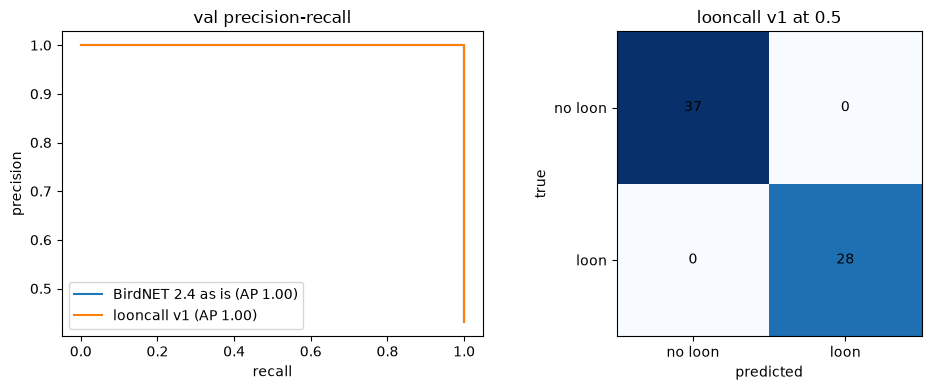

293

In [4]:
# Cell 4: logistic regression on the embeddings, against BirdNET's own loon score.
# C is picked by 5-fold CV grouped by recording, scored on average precision.
import json
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_recall_fscore_support)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import warnings; warnings.filterwarnings("ignore", category=FutureWarning)  # sklearn 1.9 API notices

THRESH = 0.5
cv = list(GroupKFold(n_splits=5).split(Xtr, ytr, groups=gtr))
clf = make_pipeline(StandardScaler(), LogisticRegressionCV(
    Cs=[1e-3, 1e-2, 1e-1, 1, 10], cv=cv, scoring="average_precision",
    class_weight="balanced", max_iter=5000))
clf.fit(Xtr, ytr)
pva = clf.predict_proba(Xva)[:, 1]
print(f"C = {clf[-1].C_[0]:g}")

RUN = ROOT / "runs/looncall_v1"; RUN.mkdir(parents=True, exist_ok=True)
metrics = {}
for name, score in (("BirdNET 2.4 as is", sva), ("looncall v1", pva)):
    p, r, f, _ = precision_recall_fscore_support(yva, score >= THRESH, average="binary",
                                                 zero_division=0)
    ap = average_precision_score(yva, score)
    metrics[name] = {"precision": p, "recall": r, "f1": f, "average_precision": ap}
    print(f"{name:18s} P {p:.3f}  R {r:.3f}  F1 {f:.3f}  AP {ap:.3f}   (threshold {THRESH})")

print("\nfalse positives on val negatives, by source")
neg_src = np.array([r["source"] for r in val])
for s in sorted(set(neg_src[yva == 0])):
    m = (neg_src == s) & (yva == 0)
    print(f"  {s:22s} {m.sum():3d} windows   BirdNET {int((sva[m] >= THRESH).sum()):2d}   "
          f"looncall {int((pva[m] >= THRESH).sum()):2d}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for name, score in (("BirdNET 2.4 as is", sva), ("looncall v1", pva)):
    pr, rc, _ = precision_recall_curve(yva, score)
    ax[0].plot(rc, pr, label=f"{name} (AP {average_precision_score(yva, score):.2f})")
ax[0].set(xlabel="recall", ylabel="precision", title="val precision-recall"); ax[0].legend()
cm = confusion_matrix(yva, pva >= THRESH)
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, v, ha="center", va="center")
ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["no loon", "loon"],
          yticklabels=["no loon", "loon"], xlabel="predicted", ylabel="true",
          title=f"looncall v1 at {THRESH}")
fig.tight_layout(); fig.savefig(RUN / "val_curves.png", dpi=100); plt.show()

(RUN / "metrics.json").write_text(json.dumps(
    {"threshold": THRESH, "C": float(clf[-1].C_[0]), "n_train": len(ytr), "n_val": len(yva),
     **metrics}, indent=2))


In [5]:
# Cell 5: save v1 as plain arrays, not a pickle -- it loads anywhere numpy does,
# across sklearn versions, and loading it cannot run code. src/detect_loon_calls.py
# applies it.
V1 = ROOT / "models/looncall/v1"; V1.mkdir(parents=True, exist_ok=True)
scaler, lr = clf[0], clf[-1]
np.savez(V1 / "weights.npz", mean=scaler.mean_.astype(np.float32),
         scale=scaler.scale_.astype(np.float32), coef=lr.coef_[0].astype(np.float32),
         intercept=np.float32(lr.intercept_[0]), threshold=np.float32(THRESH))
(V1 / "labels.yaml").write_text(yaml.safe_dump(
    {k: CFG[k] for k in ("names", "window_s", "sample_rate", "embedding")}, sort_keys=False))

w = np.load(V1 / "weights.npz")          # the arrays must reproduce the pipeline
p = 1 / (1 + np.exp(-(((Xva - w["mean"]) / w["scale"]) @ w["coef"] + w["intercept"])))
assert np.allclose(p, clf.predict_proba(Xva)[:, 1], atol=1e-4)
print(f"{V1 / 'weights.npz'}  {(V1 / 'weights.npz').stat().st_size / 1e3:.0f} kB")


/Users/nikhilkunapareddy/Documents/loonet/models/looncall/v1/weights.npz  14 kB


In [6]:
# Cell 6: the val set above is easy by construction -- positives were picked at
# BirdNET >= 0.4, negatives at < 0.02 -- so both models ace it. The harder question,
# and the one our own recordings will ask: does a call still register under the
# drone's propeller? Mix each val window with drone noise at falling SNR and score both.
# (The drone windows are in train as negatives, so looncall has heard this noise.)
import tempfile, soundfile as sf

SR = CFG["sample_rate"]
noise, _ = sf.read(RAW / "drone/drone_footage.mp3", dtype="float32")
rng = np.random.default_rng(0)
tmp = Path(tempfile.mkdtemp())

def rms(x):
    return np.sqrt(np.mean(x ** 2)) + 1e-9

SNRS = ["clean", 10, 5, 0, -5]
clips, meta = [], []
for snr in SNRS:
    for i, r in enumerate(val):
        a, _ = sf.read(RAW / r["file"], start=int(float(r["start_s"]) * SR),
                       frames=int(3 * SR), dtype="float32")
        if snr != "clean":
            o = rng.integers(0, len(noise) - len(a))
            n = noise[o:o + len(a)]
            a = a + n * (rms(a) / rms(n)) / 10 ** (snr / 20)
            a = a / max(1.0, float(np.abs(a).max()))
        path = tmp / f"{snr}_{i}.wav"
        sf.write(path, a, SR)
        clips.append(str(path)); meta.append((snr, int(r["label"])))

emb_n = {r["input"]: r["embedding"] for r in model.encode(
    clips, n_workers=4, batch_size=8).to_structured_array() if r["start_time"] == 0}
pred_n = {r["input"]: float(r["confidence"]) for r in model.predict(
    clips, top_k=None, default_confidence_threshold=None, custom_species_list=[LOON],
    n_workers=4, batch_size=8).to_structured_array() if r["start_time"] == 0}
bn = np.array([pred_n[c] for c in clips])
lc = clf.predict_proba(np.stack([emb_n[c] for c in clips]))[:, 1]
snr_col = np.array([m[0] for m in meta], dtype=object)
lab = np.array([m[1] for m in meta])

noise_rows = []
print(f"{'SNR dB':>7} | {'loon recall':^19} | {'false alarms':^19}")
print(f"{'':>7} | {'BirdNET':>9} {'looncall':>9} | {'BirdNET':>9} {'looncall':>9}")
for snr in SNRS:
    m = snr_col == snr
    row = {"snr_db": snr}
    for name, s in (("birdnet", bn), ("looncall", lc)):
        row[f"{name}_recall"] = float((s[m & (lab == 1)] >= THRESH).mean())
        row[f"{name}_false_alarm"] = float((s[m & (lab == 0)] >= THRESH).mean())
    noise_rows.append(row)
    print(f"{str(snr):>7} | {row['birdnet_recall']:9.2f} {row['looncall_recall']:9.2f} | "
          f"{row['birdnet_false_alarm']:9.2f} {row['looncall_false_alarm']:9.2f}")

m = json.loads((RUN / "metrics.json").read_text())
m["drone_noise"] = noise_rows
(RUN / "metrics.json").write_text(json.dumps(m, indent=2))


 SNR dB |     loon recall     |    false alarms    
        |   BirdNET  looncall |   BirdNET  looncall
  clean |      1.00      1.00 |      0.00      0.00
     10 |      0.75      0.86 |      0.00      0.00
      5 |      0.54      0.68 |      0.00      0.00
      0 |      0.36      0.46 |      0.00      0.00
     -5 |      0.07      0.14 |      0.00      0.00


1228